# Module Two Problem Set: Interaction Terms and Categorical Predictors

In this notebook, you have been given a set of steps that will show you how to create multiple regression models that include interaction terms and categorical predictors. It is very important to run the steps in order. Some steps depend on the outputs of earlier steps. Once you have run all the steps, you will be asked to create your own regression models to help you answer the questions in the Module Two Problem Set. You are expected to write the script yourself to answer these questions.

**<font color='red'>Important:</font>** To resume your work after a break, you must re-run all previous cells starting from Step 1. Skipping these initial setup steps will cause errors down the line.

Reminder: If you have not already reviewed the Problem Set Report template for your Module Two Problem Set, be sure to do so now. That will give you an idea of the questions you will need to answer with the outputs of this script. You should use the code you are given as reference when writing your own scripts.

### Step 1: Import Python packages
This assignment will use pandas, matplotlib and statsmodels packages in python

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as sms
import statsmodels.graphics.gofplots as smg

print("Packages imported!")

Packages imported!


### Step 2: Loading the Data Set
You are an analyst working for a car maker. You have access to a set of data that can be used to study the fuel economy of a car. Car makers are interested in studying factors that are associated with better fuel economy. This data set includes several important variables that are associated with fuel economy. You will use this dataset to create models to predict fuel economy.

This block of code will load the dataset from **mtcars.csv** file. Here are the variables contained in the dataset. 

| <div style="text-align: left"> Variable </div>  |   <div style="text-align: left"> What does it represent? </div> |
| -- | --  |
| <div style="text-align: left"> mpg </div> | <div style="text-align: left"> Fuel economy in miles/(US) gallon </div> |
| <div style="text-align: left"> cyl </div> | <div style="text-align: left"> Number of cylinders in car's engine. Values are (4, 6, 8) </div> |
| <div style="text-align: left"> disp </div> | <div style="text-align: left"> Displacement (cu.in.) measures overall volume in the engine as a factor of cylinder circumfrance, depth and total number of cylinders. This metric is a good proxy for the total amount of power the engine can generate.</div> |
| <div style="text-align: left"> hp </div> | <div style="text-align: left"> Gross horsepower measures the theoretical output of an engine’s power output.</div> |
| <div style="text-align: left"> drat </div> | <div style="text-align: left"> Rear axle ratio indicates the number of turns of the drive shaft for every one rotation of the wheel axle. A vehicle with a high ratio would provide more torque. </div> |
| <div style="text-align: left"> wt </div> | <div style="text-align: left"> Weight of the car per 1,000 lbs. </div>|
| <div style="text-align: left"> qsec </div> | <div style="text-align: left"> Quarter mile time is a performance measure of acceleration of the car.</div>|
| <div style="text-align: left"> vs </div> | <div style="text-align: left"> Engine's cylinder configuration as V-shaped or straight. Configuration offers trade offs in power/torque, design usage in terms of space/size of engine and performance or center of gravity of vehicle. Values are (0 = V-shaped, 1 = straight) </div> |
| <div style="text-align: left"> am </div> | <div style="text-align: left"> Automatic or Manual transmission. Values are (0 = automatic, 1 = manual) </div> |
| <div style="text-align: left"> gear </div> | <div style="text-align: left"> Number of gears in the transmission.</div> |

Reference:
R data sets. (1974). <i>Motor trend car road tests<i> [Data file]. Retrieved from https://www.rdocumentation.org/packages/datasets/versions/3.6.2/topics/mtcars


Click the code section below and hit the **Run** button above.

In [2]:
# Read mtcars dataset from a mtcars.csv file into Python dataframe
mtcars_df = pd.read_csv('mtcars.csv')

# This prints the column names
print("Column (variable) names:")
print(mtcars_df.columns.tolist())


# Print row and column counts
print(f"\nRow count: {mtcars_df.shape[0]}")
print(f"\nColumn count: {mtcars_df.shape[1]}")

Column (variable) names:
['car', 'mpg', 'cyl', 'disp', 'hp', 'drat', 'wt', 'qsec', 'vs', 'am', 'gear', 'carb']

Row count: 32

Column count: 12


## Step 3: Subsetting Data and Correlation Matrix
In this step, you will subset the original data set to select some variables and create a new data set. You will then print the correlation matrix for these variables in the new data set. 

Click the block of code below and hit the **Run** button above.  

In [3]:
# Create a subet of the data that includes columns fuel economy, weight and rear axle ratio
selected_vars = ['mpg', 'wt','drat']
mtcars_subset_df = mtcars_df[selected_vars].copy()
corr_matrix = mtcars_subset_df.corr()

# Print the correlation matrix
print("Correlation Matrix:")
print(corr_matrix)

Correlation Matrix:
           mpg        wt      drat
mpg   1.000000 -0.867659  0.681172
wt   -0.867659  1.000000 -0.712441
drat  0.681172 -0.712441  1.000000


## Step 4: Multiple Regression With Interaction Term
In this step, you will create a multiple regression model for fuel economy as the response variable, and weight and rear axle ratio as predictors. A numerically higher rear axle ratio sends more of the engine's available torque to the tires, thus increasing the fuel economy. We expect that the fuel economy and weight of the car are negatively correlated, meaning that as weight increases, the fuel economy decreases (or vice versa). However, the rate of decrease in fuel economy will be offset by a numerically higher rear axle ratio. This favors a multiple regression model in which the two predictor variables interact. 

The general form of this regression model is:

<br><br>
\begin{equation*}
\large E(y) = {\beta}_0\ +\ {\beta}_1\ {x}_1\ +\ {\beta}_2\ {x}_2\ +\ {\beta}_3\ {x}_1\ {x}_2
\end{equation*}
<br><br>


The prediction regression model is:

<br><br>
\begin{equation*}
\large \hat{y} = \hat{{\beta}_0} +\ \hat{{\beta}_1}\ {x}_1\ +\ \hat{{\beta}_2}\ {x}_2+\ \hat{{\beta}_3}\ {x}_1\ {x}_2
\end{equation*}
<br><br>


\begin{equation*}
\text{where } \hat{y} \text{ is the predicted value of the fuel economy,}\ {x}_1\ \text{is weight,}\ {x}_2\ \text{is rear axle ratio}
\end{equation*}

\begin{equation*}
\hat{{\beta}_0} \text{,} \hspace{0.25cm} \hat{{\beta}_1} \text{, } \hspace{0.25cm} \hat{{\beta}_2} \text{, } \hspace{0.25cm} \hat{{\beta}_3} \text{  } \text{ are estimates of}
\text{  } {\beta}_0\ \text{,} \hspace{0.25cm} {\beta}_1\ \text{,} \hspace{0.25cm} {\beta}_2\ \text{,} \hspace{0.25cm} {\beta}_3\ \text{ respectively  }
\end{equation*}
<br><br>


<br>


Click the block of code below and hit the **Run** button above.  

In [4]:
# Fit the model with individual features and their interaction
# 'wt * drat' automatically includes: wt, drat, and the interaction (wt:drat)
model1 = sms.ols(formula="mpg ~ wt * drat", data=mtcars_subset_df).fit()

# View the summary
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.800
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                     37.25
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           6.57e-10
Time:                        02:35:01   Log-Likelihood:                -76.656
No. Observations:                  32   AIC:                             161.3
Df Residuals:                      28   BIC:                             167.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.5502     12.631      0.439      0.6

### Interpretation of Beta Estimates
From the output in previous step, the prediction model equation with beta estimates rounded to 3 decimal places is:
<br><br>
\begin{equation*}
\large \hat{y} = 5.550\ +\ 3.884\ {x}_1\ +\ 8.494\ {x}_2\ -\ 2.543\ {x}_1\ {x}_2
\end{equation*}
<br><br>

\begin{equation*}
\text{where } \hat{y} \text{ is the predicted fuel efficiency,}\ {x}_1\ \text{is weight,}\ {x}_2\ \text{and rear axle ratio}  
\end{equation*}

<br>

**Interpret the estimated coefficient of rear axle ratio variable. **


* Let us assume there was no interaction present and the multiple regression model was 5.550 + 3.884 x1 + 8.494 x2. Then, the fuel economy of a car would increase on average by 8.494 for each unit increase in rear axle ratio (since 8.494 is the estimated coefficient for a rear axle ratio variable). 
<br><br>

* However, weight and rear axle ratio interact in the model in step 3, therefore the rate of change of average fuel economy with rear axle ratio depends on the weight of the car. The estimated coefficient for x2 is: 

 8.494 x2 - 2.543 (x1)(x2) = ( 8.494 - 2.543 x1 ) x2
 
 The estimated coefficient for x2 is ( 8.494 - 2.543 x1 )
 

* Suppose we have a car with weight 2.50. The estimated coeffficient for rear axle ratio can be calculated as:

 ( 8.494 - 2.543 x1 ) = 8.494 - 2.543 (2.50) = +2.1365 

 In other words, we estimate that the fuel economy of a car with weight 2,500lbs will increase by 2.1365 units for each unit  increase in rear axle ratio. Note that this is different than the 8.494 from the first bullet. This is because the multiple regression model has an interaction term between weight and rear axle ratio. 
<br><br>

* Suppose we now have a car with weight 2.32. If there were no interaction term included in the model, then the fuel economy of this car would increase on average by 8.494 for each unit increase in rear axle ratio. However, since we now have the interaction term in the model, the fuel economy of the car will increase by 8.494 - 2.543 (2.32) = 2.59 units for each unit increase in rear axle ratio. 
<br><br>

* Therefore, the rate of increase in fuel economy now varies due to the presence of an interaction term. 

## Step 5: Adding in a Categorical Predictor
In this step, you will add a categorical predictor into the multiple regression model. The transmission variable **am** is a qualitative variable with two levels; manual and automatic. Since this is a variable with two levels, we can use one dummy variable to represent it. The model will create the dummy variable automatically and will also label it appropriately. 

The general form of this regression model is:
<br><br>
\begin{equation*}
\large E(y) = {\beta}_0\ +\ {\beta}_1\ {x}_1\ +\ {\beta}_2\ {x}_2\ +\ {\beta}_3\ {x}_1\ {x}_2\ +\ {\beta}_4\ {x}_3
\end{equation*}
<br><br>

The prediction regression model is:
<br><br>
\begin{equation*}
\large \hat{y} = \hat{{\beta}_0}\ +\ \hat{{\beta}_1}\ {x}_1\ +\ \hat{{\beta}_2}\ {x}_2\ +\ \hat{{\beta}_3}\ {x}_1\ {x}_2\ +\ \hat{{\beta}_4}\ {x}_3
\end{equation*}
<br><br>

\begin{equation*}
\text{In the model above, } \hat{y} \text{ is the predicted fuel economy (mpg), x1 is weight (wt), x2 is rear axle ratio (drat), and x3 is the dummy variable for transmission (am).}
\end{equation*}

\begin{equation*}
\text{Note that am='1' for a manual transmission and am='0' for an automatic transmission.}
\end{equation*}

\begin{equation*}
\hat{{\beta}_0} \text{,} \hspace{0.25cm} \hat{{\beta}_1} \text{, } \hspace{0.25cm} \hat{{\beta}_2} \text{,} \hspace{0.25cm} \hat{{\beta}_3} \text{,} \hspace{0.25cm} \hat{{\beta}_4} \text{  } \text{ are estimates of}
\text{  } {\beta}_0\ \text{,} \hspace{0.25cm} {\beta}_1\ \text{,} \hspace{0.25cm} {\beta}_2\ \text{,} \hspace{0.25cm} {\beta}_3\ \text{,} \hspace{0.25cm} {\beta}_4\ \text{ respectively  }\\
\end{equation*}

Click the block of code below and hit the **Run** button above.  

In [5]:
# Create a subet of the data that includes columns fuel economy, weight and rear axle ratio
selected_vars = ['mpg','wt','drat','am']
mtcars_subset_df = mtcars_df[selected_vars].copy()

# Fit the model including individual features, their interaction, and the categorical transmission variable
# Wrapping am in C() treats it explicitly as a categorical factor
model2 = sms.ols(formula="mpg ~ wt * drat + C(am)", data=mtcars_subset_df).fit()

# View the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.777
Method:                 Least Squares   F-statistic:                     27.99
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           2.95e-09
Time:                        02:35:05   Log-Likelihood:                -76.165
No. Observations:                  32   AIC:                             162.3
Df Residuals:                      27   BIC:                             169.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.2470     12.914      0.251      0.8

#### Model Equation

The prediction regression model is:
<br><br>
\begin{equation*}
\large \hat{y} = 3.2470 + 4.1679 {x}_1\ + 9.5620 {x}_2\ - 2.7084 {x}_1\ {x}_2\ - 1.4641 {x}_3
\end{equation*}
<br><br>

\begin{equation*}
\text{In the model above, } \hat{y} \text{ is the predicted fuel economy (mpg), x1 is weight (wt), x2 is rear axle ratio (drat), and x3 is the dummy variable for transmission (am).}
\end{equation*}

## Step 6: Fitted Values
In this step, you will obtain the fitted values of the dataset using the model. Recall that the fitted value is just the predicted value of the dependent variable (miles per gallon) for data points from the data set. 

Click the block of code below and hit the **Run** button above.  

In [6]:
# Option 1:  Fitted (or predicted) values can be obtained using fittedvalues attribute
fitted_values = model2.fittedvalues 
print(fitted_values)

# Option 2: Using the predict method explicitly
#predicted_values = model.predict(mtcars_subset_df)

0     22.320207
1     20.689507
2     24.074750
3     19.278594
4     18.356600
5     18.194854
6     17.782915
7     19.945503
8     20.415578
9     18.545349
10    18.545349
11    15.724427
12    17.134382
13    16.927036
14    11.483047
15    10.468474
16     9.650796
17    25.654704
18    34.090685
19    28.809681
20    24.198310
21    17.996415
22    18.378418
23    16.124986
24    16.648968
25    27.478543
26    27.385767
27    28.689013
28    19.115459
29    20.784240
30    16.283559
31    21.723885
dtype: float64


## Step 7: Residuals
In this step, you will obtain the residuals using the model. Recall that the residual is the difference between the actual value and the predicted value of the dependent variable (miles per gallon). 

Click the block of code below and hit the **Run** button above.  

In [7]:
# Residuals can be onbtained using the built-in resid attribute
residuals = model2.resid
print(residuals)

0    -1.320207
1     0.310493
2    -1.274750
3     2.121406
4     0.343400
5    -0.094854
6    -3.482915
7     4.454497
8     2.384422
9     0.654651
10   -0.745349
11    0.675573
12    0.165618
13   -1.727036
14   -1.083047
15   -0.068474
16    5.049204
17    6.745296
18   -3.690685
19    5.090319
20   -2.698310
21   -2.496415
22   -3.178418
23   -2.824986
24    2.551032
25   -0.178543
26   -1.385767
27    1.710987
28   -3.315459
29   -1.084240
30   -1.283559
31   -0.323885
dtype: float64


## Step 8: Diagnostic Plots  &mdash;  Residuals against Fitted Values
In this step, you will generate plot of residuals against fitted values to test the assumption of homoscadasticity.   

Click the block of code below and hit the **Run** button above.  
NOTE: If the plot is not created, click the code section and hit the **Run** button again.

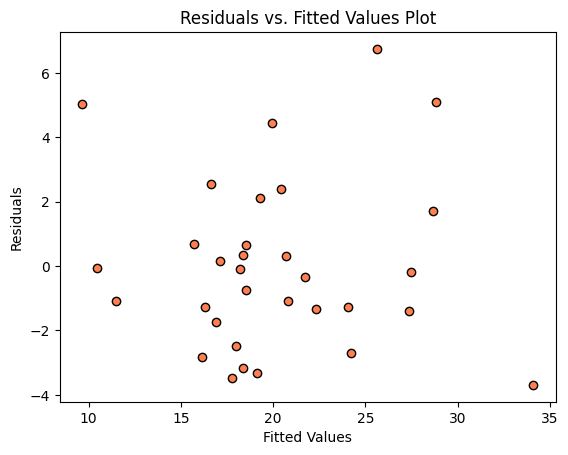

In [8]:
# Create the scatter plot
plt.scatter(x=fitted_values, y=residuals, color='coral', edgecolor='black')

# Label the axes and title
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values Plot')

# Display the plot
plt.show()

## Step 9: Diagnostic Plots  &mdash;  Q-Q Plot
In this step, you will generate a Q-Q plot to test assumptions of normality of the residuals.   

Click the block of code below and hit the **Run** button above.  
NOTE: If the plot is not created, click the code section and hit the **Run** button again.

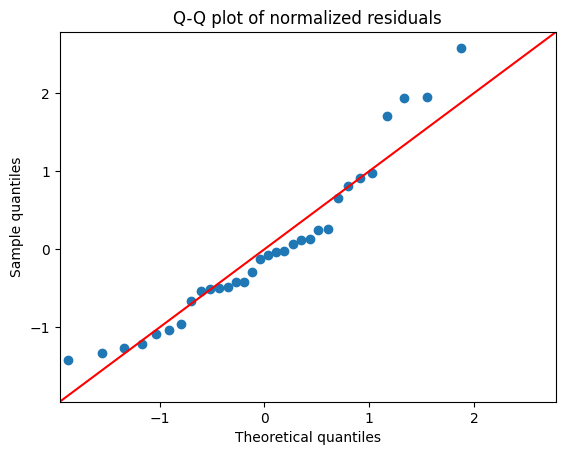

In [9]:
fig = smg.qqplot(data=residuals, line="45", fit=True)
plt.xlabel("Theoretical quantiles")
plt.ylabel("Sample quantiles")
plt.title("Q-Q plot of normalized residuals")

plt.show()

## Step 10: Confidence Interval for Parameter Estimates
In this step, you will use the **confint** function to create 90% confidence intervals for the beta parameters.  

Click the block of code below and hit the **Run** button above.  

In [10]:
# 90% confidence intervals for model parameters (note that alpha=1-CI which is alpha=1-0.90=0.10
print(model2.conf_int(alpha=0.10))

                    0          1
Intercept  -18.748775  25.242703
C(am)[T.1]  -4.184507   1.256392
wt          -2.341351  10.677099
drat         3.551620  15.572451
wt:drat     -4.600402  -0.816405


## Step 11: Predictions, Prediction Interval, and Confidence Interval
In this step, you will predict the fuel economy for a car that is manual transmission, weighs 3.88 and has rear axle ratio of 3.05. You will also obtain a 90% prediction interval and confidence interval for this prediction. Note that this observation is not from the data set that was used to create this model.

Click the block of code below and hit the **Run** button above.  

In [11]:
# Create a DataFrame with the new observation
new_data = pd.DataFrame({'wt': [3.88], 'drat': [3.05], 'am': [1]})

# Get the prediction object
prediction_obj = model2.get_prediction(new_data)

# Extract the summary frame containing the prediction and intervals
prediction_summary = prediction_obj.summary_frame(alpha=0.10) # alpha=0.10 gives 90% intervals
combined_output = pd.concat([new_data, prediction_summary], axis=1)

print(combined_output.to_string())

     wt  drat  am       mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  3.88  3.05   1  15.067217  1.664812      12.231563      17.902872      9.450082     20.684353


#### From the output in this step, the confidence and prediction intervals are as follows

- Confidence Interval is (12.232, 17.903)
- Prediction Interval is (9.450, 20.684)

## Your Code

You have been asked to create regression models in the Module Two Problem Set. Review the Problem Set Report template to see the questions you will be answering about your models.

Use the empty blocks below to write the code for your models and get outputs. Then use the outputs to answer the questions in your problem set report.

**Note: Use the + (plus) button to add new code blocks or the scissor icon to remove empty code blocks, if needed.**

In [4]:
# Import packages 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.graphics.gofplots as smg

# Load the data
mtcars = sm.datasets.get_rdataset("mtcars", "datasets").data
print(mtcars.head())
print(mtcars.shape)

                    mpg  cyl   disp   hp  drat     wt   qsec  vs  am  gear  \
rownames                                                                     
Mazda RX4          21.0    6  160.0  110  3.90  2.620  16.46   0   1     4   
Mazda RX4 Wag      21.0    6  160.0  110  3.90  2.875  17.02   0   1     4   
Datsun 710         22.8    4  108.0   93  3.85  2.320  18.61   1   1     4   
Hornet 4 Drive     21.4    6  258.0  110  3.08  3.215  19.44   1   0     3   
Hornet Sportabout  18.7    8  360.0  175  3.15  3.440  17.02   0   0     3   

                   carb  
rownames                 
Mazda RX4             4  
Mazda RX4 Wag         4  
Datsun 710            1  
Hornet 4 Drive        1  
Hornet Sportabout     2  
(32, 11)


In [5]:
# Pearson Correlations
print("Correlation between mpg and hp:", mtcars['mpg'].corr(mtcars['hp']))
print("Correlation between mpg and qsec:", mtcars['mpg'].corr(mtcars['qsec']))

Correlation between mpg and hp: -0.7761683718265865
Correlation between mpg and qsec: 0.4186840339217781


In [6]:
# Convert cyl to categorical
mtcars['cyl'] = mtcars['cyl'].astype('category')

# Fit the model with interaction term and categorical predictor
model2 = smf.ols('mpg ~ hp + qsec + hp:qsec + C(cyl)', data=mtcars).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.833
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     25.88
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           2.53e-09
Time:                        04:16:52   Log-Likelihood:                -73.770
No. Observations:                  32   AIC:                             159.5
Df Residuals:                      26   BIC:                             168.3
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      24.5056     13.186      1.858      

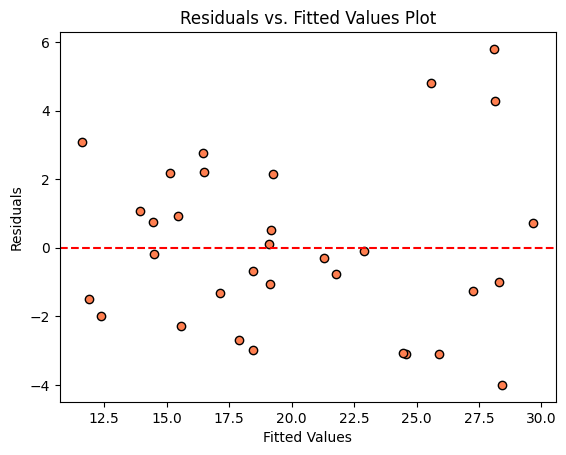

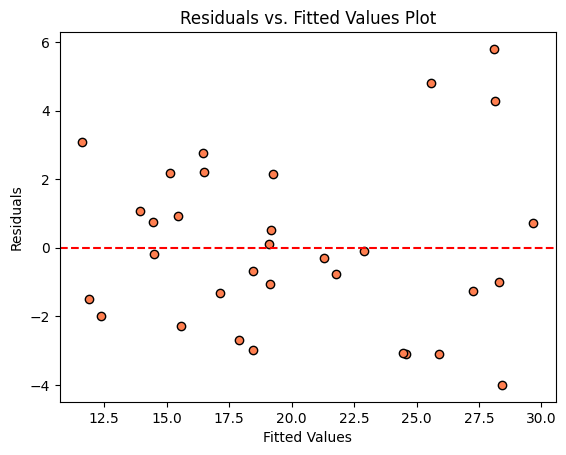

In [7]:
# Fitted values and residuals
fitted_values = model2.fittedvalues
residuals = model2.resid

# Residuals vs Fitted plot
plt.scatter(x=fitted_values, y=residuals, color='coral', edgecolor='black')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values Plot')
plt.show()

# Fitted values and residuals
fitted_values = model2.fittedvalues
residuals = model2.resid

# Residuals vs Fitted plot
plt.scatter(x=fitted_values, y=residuals, color='coral', edgecolor='black')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values Plot')
plt.show()

In [8]:
# Prediction for a car with hp=175, qsec=14.2, cyl=6
new_data = pd.DataFrame({
    'hp': [175],
    'qsec': [14.2],
    'cyl': [6]
})
new_data['cyl'] = pd.Categorical(new_data['cyl'], categories=mtcars['cyl'].cat.categories)

prediction = model2.get_prediction(new_data)
pred_summary = prediction.summary_frame(alpha=0.05)  # 95% intervals
print(pred_summary)

        mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  21.342443  1.627776      17.996501      24.688385     14.876407   

   obs_ci_upper  
0     27.808479  


## End of Module Two Jupyter Notebook
Attach the HTML output along with your problem set report for the Module Two Problem Set. The HTML output can be downloaded by clicking **File**, then **Download as**, then **HTML**. Be sure to answer all of the questions in your problem set report.